In [1]:
from astropy import units as u
from galpy.potential import ChandrasekharDynamicalFrictionForce as CDFF, NFWPotential, vcirc, FDMDynamicalFrictionForce as FDM_DF
from galpy.orbit import Orbit
import numpy as np
import matplotlib.pyplot as plt
from colossus.halo import concentration, profile_nfw
from colossus.cosmology import cosmology
from joblib import Parallel, delayed
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from halotools.sim_manager import FakeSim
from halotools.empirical_models import PrebuiltSubhaloModelFactory
from galpy.potential import (TwoPowerSphericalPotential, AnySphericalPotential,evaluateDensities)
from scipy.optimize import minimize, fsolve
from math import pi
import sys
import pandas as pd
import time
from astropy.constants import G
import matplotlib.lines as mlines
from scipy.stats import gaussian_kde
from matplotlib.ticker import AutoMinorLocator
from matplotlib.ticker import MultipleLocator
from scipy.signal import argrelextrema
cosmology.setCosmology('planck15')

In [3]:
#parameters m22 NFW
Ms=2.39e7
rhm=0.01
RGC = np.array([1.6, 1.05, 0.43, 0.24, 1.43]) #*(2/np.sqrt(3))
MGC = np.array([0.37e5, 1.82e5, 3.63e5, 1.32e5, 1.78e5])
ts=np.linspace(0,10,1001)*u.Gyr
threshold=0.2
N_amas=len(RGC)
e=0
a=np.sqrt(1+e)

#stellar mass
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
M=10**model.mean_log_halo_mass(logMs)

#potential
Mh=M*0.704
c=concentration.concentration(Mh,'vir',0,model='prada12')
p_nfw=profile_nfw.NFWProfile(M=Mh,c=c,z=0,mdef='vir')
rs=p_nfw.par['rs']/0.704
A=np.log(1+c)-c/(1+c)
NFW_pot=NFWPotential(amp=M/A*u.Msun,a=rs*u.kpc)

#orbits
os=[[r*u.kpc,0*u.km/u.s,a*vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg] for r in RGC] #np.sqrt(1+e)*

#globular cluster selection
def cdm(i):
    orb=Orbit(os[i])
    cdf=CDFF(GMs=MGC[i]*u.Msun,rhm=rhm*u.kpc,dens=NFW_pot)
    orb.integrate(ts,NFW_pot+cdf,method='dop853_c')
    ap = argrelextrema(orb.r(ts), np.greater)[0]
    return np.min(orb.r(ts)[ap])<threshold
    
valid=np.where(Parallel(n_jobs=-1)(delayed(cdm)(i) for i in range(len(RGC))))[0]
RGC=RGC[valid]
MGC=MGC[valid]
os=[os[i] for i in valid]
print("Pourcentage d'amas conservés : ",len(RGC)/N_amas*100,"%")

def test(i,m22):
    orb=Orbit(os[i])
    fdf=FDM_DF(GMs=MGC[i]*u.Msun,rhm=rhm*u.kpc,dens=NFW_pot,m=(m22*1e-22)*u.eV)
    orb.integrate(ts,NFW_pot+fdf,method='dop853_c')
    ap = argrelextrema(orb.r(ts), np.greater)[0]
    return np.min(orb.r(ts)[ap])<threshold

def find_m22(i,lo=0.1,hi=50,eps=0.001):
    while hi-lo>eps:
        mid=0.5*(lo+hi)
        if test(i,mid):
            hi=mid
        else:
            lo=mid
    return 0.5*(lo+hi)

m22_crit=Parallel(n_jobs=-1)(delayed(find_m22)(i) for i in range(len(RGC)))
print(m22_crit,"\n m22 = ",min(m22_crit))

ValueError: zero-size array to reduction operation minimum which has no identity

In [ ]:
me3D=2.815581512451172
me2D=2.2353843688964847
m3D=1.7290443420410158
m2D=1.3102668762207033
np.savez("m22_NFW_fornax_dwarf.npz",m2D=m2D,m3D=m3D,me2D=me2D,me3D=me3D)

In [2]:
#same but with Core profile

def zeta(z, Omega_m):
    return (18 * np.pi**2 + 82 * (Omega_m - 1) - 39 * (Omega_m - 1)**2) / Omega_m

def r_c(z, M_h, m_22, Omega_m):
    return (1.6 / np.sqrt(1 + z)) * (zeta(z, Omega_m) / zeta(0, Omega_m0))**(-1/6) * (M_h / 1e9)**(-1/3) * m_22**-1

def rho2_z(r_c, m_22, z):
    return 1.9 * (10 * m_22)**-2 * r_c**-4 * 1e9 / ((1 + z)**3)

zgo = 0
cosmo = cosmology.setCosmology('planck18')
Omega_m0 = cosmo.Om(zgo)

def FDMhalo(m22, M):

    Mh=M*0.704
    rc1 = r_c(zgo, M, m22, Omega_m0)
    rhoFDM = rho2_z(rc1, m22, zgo)
    AmpFDM = rhoFDM * 4 * pi * rc1**3

    rc2 = r_c(zgo, M, m22/10, Omega_m0)
    rhoFDM2 = rho2_z(rc2, m22/10, zgo)
    AmpFDM2 = rhoFDM2 * 4 * pi * rc2**3
    

    C2 = concentration.concentration(M*0.704, 'vir', zgo, model='prada12')
    p_nfw = profile_nfw.NFWProfile(M=M*0.704, c=C2, z=zgo, mdef='vir')
    rs = p_nfw.par['rs'] / 0.704
    A=np.log(1+C2)-C2/(1+C2)

    DMhalo2 = NFWPotential(amp=M/A * u.Msun, a=rs*u.kpc)
    r_vals = np.logspace(np.log10(0.001), np.log10(1000), 200)
    FDMhalo_soliton = AnySphericalPotential(dens=lambda r: rhoFDM / ((1 + 0.091 * (r / rc1)**2)**8))

    def cost(params):
        psi, gamma, eta = params
        if psi <= 0 or gamma <= 0 or eta <= 0:
            return np.inf

        def equation(alpha):
            FDMhalo3 = TwoPowerSphericalPotential(amp=psi * AmpFDM2 * (alpha**3) * u.Msun, a=alpha * rc2 * u.kpc, alpha=0, beta=3)
            dens_FDM3 = evaluateDensities(FDMhalo3, 100 * u.kpc, 0 * u.kpc)
            dens_CDM = evaluateDensities(DMhalo2, 100 * u.kpc, 0 * u.kpc)
            return (dens_FDM3 - dens_CDM) / dens_CDM

        try:
            alpha_sol = fsolve(equation, 10)[0]
        except:
            return np.inf

        FDMhalo3 = TwoPowerSphericalPotential(amp=psi * AmpFDM2 * (alpha_sol**3) * u.Msun, a=alpha_sol * rc2 * u.kpc, alpha=0, beta=3)
        CoreFDM = TwoPowerSphericalPotential(amp=AmpFDM * (gamma**3) * u.Msun, a=gamma * rc1 * u.kpc, alpha=0, beta=eta)
        total_ref = np.array([evaluateDensities(FDMhalo_soliton, r, 0) + evaluateDensities(FDMhalo3, r * u.kpc, 0 * u.kpc) * 1e9 for r in r_vals])
        total_test = np.array([evaluateDensities(CoreFDM, r * u.kpc, 0 * u.kpc) * 1e9 + evaluateDensities(FDMhalo3, r * u.kpc, 0 * u.kpc) * 1e9 for r in r_vals])
        return np.mean((np.log10(total_ref + 1e-30) - np.log10(total_test + 1e-30))**2)

    result = minimize(cost, x0=[0.5, 12.0, 20.0], bounds=[(0.0001, 0.7 * (1e10 / M) * (10 / m22)), (1, 10), (3, 10)], method='L-BFGS-B')
    psi_opt, gamma_opt, eta_opt = result.x

    def equation(alpha):
        FDMhalo3 = TwoPowerSphericalPotential(amp=psi_opt * AmpFDM2 * (alpha**3) * u.Msun, a=alpha * rc2 * u.kpc, alpha=0, beta=3)
        dens_FDM3 = evaluateDensities(FDMhalo3, 100 * u.kpc, 0 * u.kpc) * 1e9
        dens_CDM = evaluateDensities(DMhalo2, 100 * u.kpc, 0 * u.kpc) * 1e9
        return (dens_FDM3 - dens_CDM) / dens_CDM

    alpha_final = fsolve(equation, 10)[0]
    FDMhalo3 = TwoPowerSphericalPotential(amp=psi_opt * AmpFDM2 * (alpha_final**3) * u.Msun, a=alpha_final * rc2 * u.kpc, alpha=0, beta=3)
    CoreFDM = TwoPowerSphericalPotential(amp=(gamma_opt**3) * AmpFDM * u.Msun, a=gamma_opt * rc1 * u.kpc, alpha=0, beta=eta_opt)
    return CoreFDM + FDMhalo3


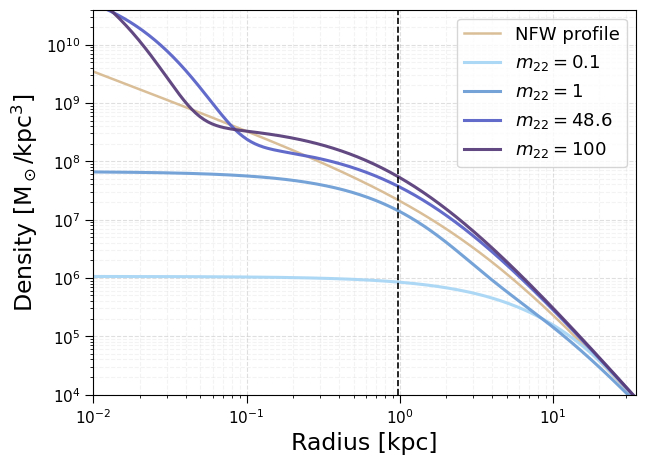

In [9]:
m22 = [0.1, 1, 48.6,100]  # e-22
M = 1e10
r = np.logspace(-2, 2, 300)
#colors = ["gold","orange", "#D64545", "purple"]
colors = ["#A9D6F5", "#6E9ED6", "#5A63C8", "#5A3F7A"]


C2 = concentration.concentration(M * 0.704, 'vir', zgo, model='prada12')
p_nfw = profile_nfw.NFWProfile(M=M * 0.704, c=C2, z=zgo, mdef='vir')
rs = p_nfw.par['rs'] / 0.704
A = np.log(1 + C2) - C2 / (1 + C2)
DMhalo_NFW = NFWPotential(amp=M / A * u.Msun, a=rs * u.kpc)


plt.figure(figsize=(7,5))

rho_nfw = np.array([evaluateDensities(DMhalo_NFW, ri * u.kpc, 0 * u.kpc) * 1e9 for ri in r])
plt.loglog(r, rho_nfw, color="#D9BE98", lw=1.8, ls="-",label="NFW profile")

for i, m in enumerate(m22):
    pot = FDMhalo(m, M)
    rho = np.array([evaluateDensities(pot, ri * u.kpc, 0 * u.kpc) * 1e9 for ri in r])
    plt.loglog(r, rho, color=colors[i], lw=2.2,alpha=0.95, label=rf"$m_{{22}}={m}$")
plt.axvline(0.98,color="black",linestyle="--",linewidth=1.2)
plt.tick_params(axis='both', which='major', labelsize=11, length=6)
#ax.tick_params(axis='both', which='minor', length=3)
plt.xlabel("Radius [kpc]", fontsize=17)
plt.ylabel(r"Density $\mathrm{[M_\odot/kpc^3]}$", fontsize=17)
plt.xlim(0.01, 35)
plt.ylim(1e4,4e10)
#plt.grid(True, which="both", ls="--", alpha=0.4)
plt.grid(True, which='major',ls="--", alpha=0.4)
plt.grid(True, which='minor',ls="--", alpha=0.15)
plt.legend(fontsize=13)
plt.savefig("rho_NFW.png", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
Ms=2.39e7
rhm=0.01
RGC=np.array([1.6,1.05,0.43,0.24,1.43])*(2/np.sqrt(3))
MGC=np.array([0.37e5,1.82e5,3.63e5,1.32e5,1.78e5])
ts=np.linspace(0,10,1001)*u.Gyr
threshold=0.2
N_amas=len(RGC)
e=0
a=np.sqrt(1+e)
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
M=10**model.mean_log_halo_mass(logMs)


os=[[r*u.kpc,0*u.km/u.s,a*vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg] for r in RGC]

def fall(i):
    orb=Orbit(os[i])
    cdf=CDFF(GMs=MGC[i]*u.Msun,rhm=rhm*u.kpc,dens=NFW_pot)
    orb.integrate(ts,NFW_pot+cdf,method='dop853_c')
    return np.min(orb.r(ts))<threshold

valid=np.where(Parallel(n_jobs=-1)(delayed(fall)(i) for i in range(len(RGC))))[0]
RGC=RGC[valid]
MGC=MGC[valid]
os=[os[i] for i in valid]
print("Pourcentage d'amas conservés :",len(RGC)/N_amas*100,"%")

def test(i,m22):
    cosmology.setCosmology('planck15')
    pot=FDMhalo(m22,M)
    o=[RGC[i]*u.kpc,0*u.km/u.s,a*vcirc(pot,RGC[i]*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]
    orb=Orbit(o)
    fdf=FDM_DF(GMs=MGC[i]*u.Msun,rhm=rhm*u.kpc,dens=pot,m=(m22*1e-22)*u.eV)
    orb.integrate(ts,pot+fdf,method='dop853_c')
    return np.min(orb.r(ts))<threshold

def find_m22(i,lo=0.1,hi=50,eps=0.001):
    while hi-lo>eps:
        mid=0.5*(lo+hi)
        if test(i,mid):
            hi=mid
        else:
            lo=mid
    return 0.5*(lo+hi)

m22_crit=Parallel(n_jobs=-1)(delayed(find_m22)(i) for i in range(len(RGC)))
print(m22_crit,"\nm22 =",min(m22_crit))

Pourcentage d'amas conservés : 40.0 %
[1.5143257141113282, 1.3315864562988282] 
m22 = 1.3315864562988282


In [6]:
Ms=2.39e7          #m22 epicentre
rhm=0.01
RGC=np.array([1.6,1.05,0.43,0.24,1.43])*(2/np.sqrt(3))
MGC=np.array([0.37e5,1.82e5,3.63e5,1.32e5,1.78e5])
ts=np.linspace(0,10,1001)*u.Gyr
threshold=0.2
N_amas=len(RGC)
e=0.5
a=np.sqrt(1+e)
halocat=FakeSim()
model=PrebuiltSubhaloModelFactory('behroozi10')
model.populate_mock(halocat)
logMs=np.log10(Ms)
M=10**model.mean_log_halo_mass(logMs)


os=[[r*u.kpc,0*u.km/u.s,a*vcirc(NFW_pot,r*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg] for r in RGC]

def fall(i):
    orb=Orbit(os[i])
    cdf=CDFF(GMs=MGC[i]*u.Msun,rhm=rhm*u.kpc,dens=NFW_pot)
    orb.integrate(ts,NFW_pot+cdf,method='dop853_c')
    ap = argrelextrema(orb.r(ts), np.greater)[0]
    return np.min(orb.r(ts)[ap])<threshold

valid=np.where(Parallel(n_jobs=-1)(delayed(fall)(i) for i in range(len(RGC))))[0]
RGC=RGC[valid]
MGC=MGC[valid]
os=[os[i] for i in valid]
print("Pourcentage d'amas conservés :",len(RGC)/N_amas*100,"%")

def test(i,m22):
    cosmology.setCosmology('planck15')
    pot=FDMhalo(m22,M)
    o=[RGC[i]*u.kpc,0*u.km/u.s,a*vcirc(pot,RGC[i]*u.kpc)*u.km/u.s,0*u.kpc,0*u.km/u.s,0*u.deg]
    orb=Orbit(o)
    fdf=FDM_DF(GMs=MGC[i]*u.Msun,rhm=rhm*u.kpc,dens=pot,m=(m22*1e-22)*u.eV)
    orb.integrate(ts,pot+fdf,method='dop853_c')
    ap = argrelextrema(orb.r(ts), np.greater)[0]
    return np.min(orb.r(ts)[ap])<threshold

def find_m22(i,lo=0.1,hi=50,eps=0.001):
    while hi-lo>eps:
        mid=0.5*(lo+hi)
        if test(i,mid):
            hi=mid
        else:
            lo=mid
    return 0.5*(lo+hi)

m22_crit=Parallel(n_jobs=-1)(delayed(find_m22)(i) for i in range(len(RGC)))
print(m22_crit,"\nm22 =",min(m22_crit))



Pourcentage d'amas conservés : 40.0 %
[2.2445213317871096, 2.2399528503417967] 
m22 = 2.2399528503417967


In [ ]:
mce3D=2.26203384399414
mce2D=1.9270118713378908
mc3D=1.6399589538574217
mc2D=1.3315864562988282
np.savez("m22_Core_fornax_dwarf.npz",mc2D=mc2D,mc3D=mc3D,mce2D=mce2D,mce3D=mce3D)